# Phishing URL Detection

## 1. Problem Definition

Classify a URL as legitimate (0) or phishing (1) using features from its text.

- Input: raw URL
- Planned output: class and phishing probability
- Main metric: phishing recall at a target FPR of 5%
- Other metrics: precision, F1, average precision, ROC-AUC and confusion matrix

We will select the threshold on validation data and report the actual test FPR. This notebook covers Steps 1–7.

## 2. Dataset

[Malicious URLs dataset — Kaggle](https://www.kaggle.com/datasets/sid321axn/malicious-urls-dataset)

The file has 651,191 rows with `url` and `type`. We keep `benign` and `phishing` and exclude the other types.

Keep `malicious_phish.csv` beside the notebook and open that folder in VS Code. Required packages are listed in `requirements.txt`.

In [14]:
%pip install tldextract

In [15]:
import re
import ipaddress
import math
from collections import Counter
from pathlib import Path
from urllib.parse import urlsplit

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tldextract
from sklearn.model_selection import StratifiedGroupKFold

pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

ext = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=True)

In [16]:
data_path = Path("malicious_phish.csv")
df = pd.read_csv("malicious_phish.csv")
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
df.head()

Rows: 651191
Columns: ['url', 'type']


,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign
3,http://www.garage-pirenne.be/index.php?option=...,defacement
4,http://adventure-nicaragua.net/index.php?optio...,defacement


In [17]:
df["type"].value_counts()

,count
type,
benign,428103
defacement,96457
phishing,94111
malware,32520


## 3. Data Understanding

Check column types, missing values, class counts and repeated URLs before cleaning.

In [18]:
df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 651191 entries, 0 to 651190
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   url     651191 non-null  object
 1   type    651191 non-null  object
dtypes: object(2)
memory usage: 9.9+ MB


,0
url,0
type,0


In [19]:
df.sample(5, random_state=42)

,url,type
536448,http://37.49.226.178/deusbins/deus.sh4,malware
40630,medical-dictionary.thefreedictionary.com/Galt+...,benign
630496,www.jscape.com/sshfactory/,phishing
426724,http://www.wsnc.org.au/component/jcalpro/view/983,defacement
184034,virtualtourist.com/travel/North_America/Canada...,benign


In [20]:
print("Repeated rows:", df.duplicated().sum())
print("Repeated URLs:", df["url"].duplicated().sum())

tmp = df.groupby("url")["type"].nunique()
print("URLs with multiple types:", (tmp > 1).sum())

Repeated rows: 10066
Repeated URLs: 10072
URLs with multiple types: 6


## 4. Data Cleaning

Remove missing or blank URLs, control-character rows, conflicting labels and duplicates. Strip outer whitespace and keep path/query text unchanged. Long URLs are retained.

In [21]:
data = df.loc[df["type"].isin(["benign", "phishing"]), ["url", "type"]].copy()
print("Binary rows before cleaning:", len(data))

n = len(data)
data = data.dropna(subset=["url", "type"])
data["url"] = data["url"].str.strip()
data = data[data["url"] != ""].copy()
print("Missing or blank rows removed:", n - len(data))

tmp = data["url"].str.contains(r"[\x00-\x1f\x7f-\x9f]", regex=True)
print("Rows with control characters:", tmp.sum())
data = data.loc[~tmp].copy()

data["label"] = data["type"].map({"benign": 0, "phishing": 1})

Binary rows before cleaning: 522214
Missing or blank rows removed: 0
Rows with control characters: 102


In [22]:
tmp = data.groupby("url")["label"].nunique()
bad = tmp[tmp > 1].index
print("Conflicting URLs:", len(bad))

n = len(data)
data = data.loc[~data["url"].isin(bad)].copy()
print("Conflicting rows removed:", n - len(data))

n = len(data)
data = data.drop_duplicates(subset="url").reset_index(drop=True)
print("Repeated rows removed:", n - len(data))

Conflicting URLs: 6
Conflicting rows removed: 12
Repeated rows removed: 42


### URL parsing

Use a temporary `//` prefix for URLs without a scheme. Parse the host and use the Public Suffix List to find the registrable domain for grouping.

Private suffixes are included so separate sites such as `alice.github.io` and `bob.github.io` form separate groups.

In [23]:
def parse_url(url):
    tmp = url
    if not re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", url) and not url.startswith("//"):
        tmp = "//" + url
    return urlsplit(tmp)

arr = []
for url in data["url"]:
    arr.append(parse_url(url).hostname or "")

data["host"] = arr
print("Rows without a host:", (data["host"] == "").sum())
data = data[data["host"] != ""].copy()

arr = []
for host in data["host"]:
    tmp = ext(host)
    arr.append(tmp.top_domain_under_public_suffix or host)

data["domain"] = arr
data = data[["url", "host", "domain", "label"]].reset_index(drop=True)

print("Clean rows:", len(data))
print("Missing values:", data.isna().sum().sum())
print("Repeated URLs:", data["url"].duplicated().sum())
data["label"].value_counts().sort_index()

Rows without a host: 0
Clean rows: 522058
Missing values: 0
Repeated URLs: 0


,count
label,
0,428071
1,93987


## 5. Train / Test Split

Keep URLs from the same registrable domain in one set. Use the first fold of a five-fold stratified group split, with seed 42, for roughly 80% train and 20% test.

Check class proportions and overlap. Use training data for EDA and later model selection.

In [24]:
split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(split.split(data, data["label"], groups=data["domain"]))

train_df = data.iloc[train_idx].reset_index(drop=True)
test_df = data.iloc[test_idx].reset_index(drop=True)

tmp = pd.DataFrame({
    "train_count": train_df["label"].value_counts().sort_index(),
    "test_count": test_df["label"].value_counts().sort_index(),
    "train_percent": train_df["label"].value_counts(normalize=True).sort_index() * 100,
    "test_percent": test_df["label"].value_counts(normalize=True).sort_index() * 100
})
print("Train:", len(train_df))
print("Test:", len(test_df))
print("Test share:", round(len(test_df) / len(data) * 100, 2), "%")
tmp.round(2)

Train: 419021
Test: 103037
Test share: 19.74 %


,train_count,test_count,train_percent,test_percent
label,,,,
0,342918,85153,81.84,82.64
1,76103,17884,18.16,17.36


In [25]:
print("URL overlap:", len(set(train_df["url"]) & set(test_df["url"])))
print("Domain overlap:", len(set(train_df["domain"]) & set(test_df["domain"])))

URL overlap: 0
Domain overlap: 0


## 6. Exploratory Data Analysis

Compare class counts, URL lengths and character counts using training data only.

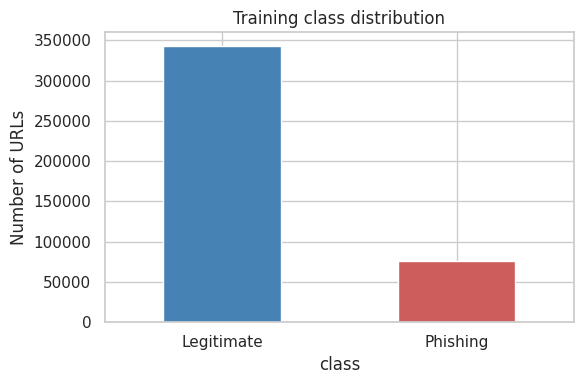

,count
class,
Legitimate,81.84
Phishing,18.16


In [26]:
eda = train_df.copy()
eda["class"] = eda["label"].map({0: "Legitimate", 1: "Phishing"})
eda["url_length"] = eda["url"].str.len()
eda["dot_count"] = eda["url"].str.count(r"\.")
eda["digit_count"] = eda["url"].str.count(r"[0-9]")
eda["hyphen_count"] = eda["url"].str.count("-")
eda["at_count"] = eda["url"].str.count("@")
eda["scheme_known"] = eda["url"].str.contains(r"^[a-zA-Z][a-zA-Z0-9+.-]*://")
eda["has_https"] = eda["url"].str.lower().str.startswith("https://")

tmp = eda["class"].value_counts().reindex(["Legitimate", "Phishing"])
tmp.plot(kind="bar", color=["steelblue", "indianred"], rot=0, figsize=(6, 4))
plt.title("Training class distribution")
plt.ylabel("Number of URLs")
plt.tight_layout()
plt.show()

(tmp / tmp.sum() * 100).round(2)

In [27]:
eda.groupby("class")["url_length"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
Legitimate,342918.0,57.84,44.89,6.0,32.0,46.0,71.0,2175.0
Phishing,76103.0,44.54,40.76,2.0,26.0,34.0,48.0,1779.0


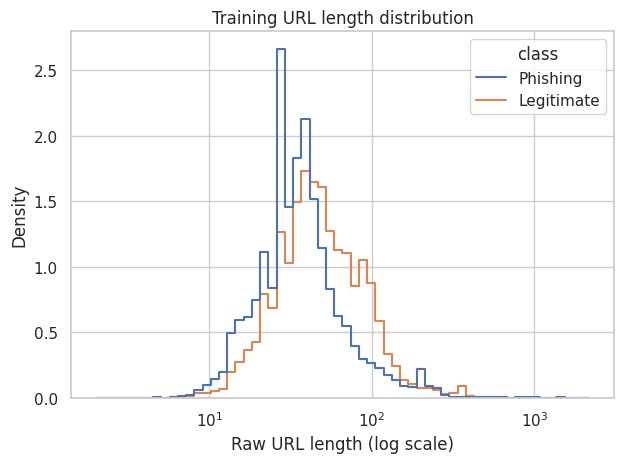

In [28]:
sns.histplot(data=eda, x="url_length", hue="class", bins=60, log_scale=True,
             stat="density", common_norm=False, element="step", fill=False)
plt.xlabel("Raw URL length (log scale)")
plt.title("Training URL length distribution")
plt.tight_layout()
plt.show()

In [29]:
cols = ["url_length", "dot_count", "digit_count", "hyphen_count", "at_count"]
eda.groupby("class")[cols].agg(["mean", "median"]).round(2)

url_length        dot_count        digit_count        hyphen_count  \
                 mean median      mean median        mean median         mean   
class                                                                           
Legitimate      57.84   46.0      1.95    2.0        5.63    1.0         1.85   
Phishing        44.54   34.0      2.50    2.0        3.46    0.0         0.46   

                  at_count         
           median     mean median  
class                              
Legitimate    0.0     0.00    0.0  
Phishing      0.0     0.01    0.0

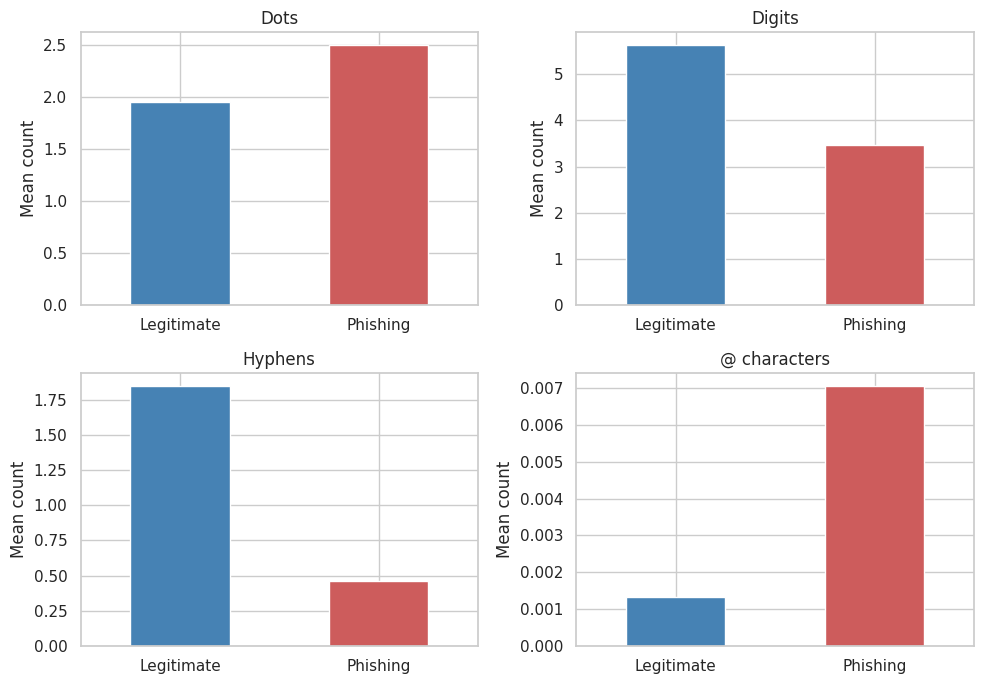

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
cols = ["dot_count", "digit_count", "hyphen_count", "at_count"]
names = ["Dots", "Digits", "Hyphens", "@ characters"]

for i in range(len(cols)):
    ax = axes.flat[i]
    tmp = eda.groupby("class")[cols[i]].mean().reindex(["Legitimate", "Phishing"])
    tmp.plot(kind="bar", ax=ax, color=["steelblue", "indianred"], rot=0)
    ax.set_title(names[i])
    ax.set_xlabel("")
    ax.set_ylabel("Mean count")

plt.tight_layout()
plt.show()

### Scheme recording

Missing schemes mean unknown protocol. Compare recording rates by class. Exclude `scheme_known` and `has_https` from model inputs because recording rates differ across classes.

Final character counts also exclude the leading scheme.

In [31]:
(eda.groupby("class")[["scheme_known", "has_https"]].mean() * 100).round(2)

,scheme_known,has_https
class,,
Legitimate,8.26,0.35
Phishing,25.41,6.27


In [32]:
tmp = eda.groupby("class")["url_length"].agg(["mean", "median"]).round(2)
print(tmp.to_string())
print("Longest training URL:", eda["url_length"].max())
print("Training domains:", eda["domain"].nunique())
print("Largest training domain group:", eda["domain"].value_counts().iloc[0])

             mean  median
class                    
Legitimate  57.84    46.0
Phishing    44.54    34.0
Longest training URL: 2175
Training domains: 123025
Largest training domain group: 13422


### EDA observations

- Training has 342,456 legitimate and 75,189 phishing URLs, about 82% / 18%.
- Legitimate URLs are longer on average: 57.75 versus 45.37 characters. The medians are 46 and 34.
- Explicit schemes appear in 8.24% of legitimate and 26.33% of phishing URLs. Explicit HTTPS appears in 0.36% and 6.96%.
- The largest training domain group contains 8,633 URLs.

## 7. Feature Engineering

Use the same extractor for train and test. It computes features from each URL without fitting anything to the data.

| Features | What they measure |
| --- | --- |
| url_length | Length after removing the leading scheme or `//` |
| domain_length | Full hostname length, including subdomains |
| path_length, query_length | Parsed path and query lengths |
| Character counts | Dots, digits, hyphens, `@`, slashes and other punctuation |
| special_count | Total characters from `.-/@?=&%_:+~#` |
| subdomain_count | Subdomain labels from the Public Suffix List, including `www` |
| host_digit_count, host_hyphen_count | Digits and hyphens in the host |
| digit_ratio | Digits divided by scheme-free URL length |
| path_depth, param_count | Nonempty path segments and query fields |
| has_ip, has_punycode | IP host and `xn--` hostname labels |
| suspicious_count | Fixed keywords present in the URL |
| host_suspicious_count, path_suspicious_count | Keywords present in the host and path separately |
| host_entropy | Shannon entropy of hostname characters, in bits |
| tld, tld_length | Public suffix text and its character length |

Keywords are counted once each using substring matching. Entropy measures character diversity; a high value does not by itself mean phishing.

`tld` is categorical and will be encoded in preprocessing. All other predictors are numeric. `scheme_known` and `has_https` remain audit columns.

In [33]:
words = ["login", "signin", "verify", "account", "password",
         "secure", "update", "banking", "confirm", "wallet"]

def entropy(s):
    n = len(s)
    if n == 0:
        return 0
    cnt = Counter(s)
    val = 0
    for v in cnt.values():
        p = v / n
        val -= p * math.log2(p)
    return val

def get_features(url):
    p = parse_url(url)
    host = p.hostname or ""
    tmp = ext(host)
    text = re.sub(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", "", url)
    if text.startswith("//"):
        text = text[2:]
    n = len(text)

    digits = 0
    special = 0
    for c in text:
        if c in "0123456789":
            digits += 1
        if c in ".-/@?=&%_:+~#":
            special += 1

    low = text.lower()
    path_low = p.path.lower()
    cnt = 0
    host_cnt = 0
    path_cnt = 0
    for word in words:
        if word in low:
            cnt += 1
        if word in host:
            host_cnt += 1
        if word in path_low:
            path_cnt += 1

    sub = 0
    if tmp.subdomain:
        sub = len(tmp.subdomain.split("."))

    depth = 0
    for part in p.path.split("/"):
        if part:
            depth += 1

    params = 0
    for part in p.query.split("&"):
        if part:
            params += 1

    is_ip = 0
    try:
        ipaddress.ip_address(host)
        is_ip = 1
    except ValueError:
        pass

    punycode = 0
    for part in host.split("."):
        if part.startswith("xn--"):
            punycode = 1

    return {
        "url_length": n,
        "domain_length": len(host),
        "path_length": len(p.path),
        "query_length": len(p.query),
        "dot_count": text.count("."),
        "digit_count": digits,
        "hyphen_count": text.count("-"),
        "at_count": text.count("@"),
        "slash_count": text.count("/"),
        "question_count": text.count("?"),
        "equal_count": text.count("="),
        "amp_count": text.count("&"),
        "percent_count": text.count("%"),
        "underscore_count": text.count("_"),
        "special_count": special,
        "subdomain_count": sub,
        "host_digit_count": len(re.findall(r"[0-9]", host)),
        "host_hyphen_count": host.count("-"),
        "digit_ratio": digits / n,
        "path_depth": depth,
        "param_count": params,
        "has_ip": is_ip,
        "has_punycode": punycode,
        "suspicious_count": cnt,
        "host_suspicious_count": host_cnt,
        "path_suspicious_count": path_cnt,
        "host_entropy": entropy(host),
        "tld": tmp.suffix,
        "tld_length": len(tmp.suffix),
        "scheme_known": int(bool(p.scheme)),
        "has_https": int(p.scheme.lower() == "https")
    }

### Extraction examples

Use reserved example addresses to check parsing and the new features.

In [34]:
urls = [
    "https://shop.example.co.uk/login?id=12&next=home",
    "shop.example.co.uk/login?id=12&next=home",
    "http://192.0.2.1/verify/account",
    "https://shop.example.com@other.example.net/confirm",
    "https://xn--bcher-kva.example/",
    "service.example.com/path?next=https://other.example.org"
]

arr = []
for url in urls:
    tmp = get_features(url)
    tmp["url"] = url
    arr.append(tmp)

pd.DataFrame(arr).set_index("url")

,url_length,domain_length,path_length,query_length,dot_count,digit_count,hyphen_count,at_count,slash_count,question_count,equal_count,amp_count,percent_count,underscore_count,special_count,subdomain_count,host_digit_count,host_hyphen_count,digit_ratio,path_depth,param_count,has_ip,has_punycode,suspicious_count,host_suspicious_count,path_suspicious_count,host_entropy,tld,tld_length,scheme_known,has_https
url,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
https://shop.example.co.uk/login?id=12&next=home,40,18,6,15,3,2,0,0,1,1,2,1,0,0,8,1,0,0,0.05,1,2,0,0,1,0,1,3.572431,co.uk,5,1,1
shop.example.co.uk/login?id=12&next=home,40,18,6,15,3,2,0,0,1,1,2,1,0,0,8,1,0,0,0.05,1,2,0,0,1,0,1,3.572431,co.uk,5,0,0
http://192.0.2.1/verify/account,24,9,15,0,3,6,0,0,2,0,0,0,0,0,5,0,6,0,0.25,2,0,1,0,2,0,2,2.197160,,0,1,0
https://shop.example.com@other.example.net/confirm,42,17,8,0,4,0,0,1,1,0,0,0,0,0,6,1,0,0,0.00,1,0,0,0,1,0,1,3.381580,net,3,1,1
https://xn--bcher-kva.example/,22,21,1,0,1,0,3,0,1,0,0,0,0,0,5,1,0,3,0.00,0,0,0,1,0,0,0,3.748995,,0,1,1
service.example.com/path?next=https://other.example.org,55,19,5,30,4,0,0,0,3,1,1,0,0,0,10,1,0,0,0.00,1,1,0,0,0,0,0,3.511085,com,3,0,0


In [35]:
arr = []
for url in train_df["url"]:
    arr.append(get_features(url))
train_features = pd.DataFrame(arr, index=train_df.index)

arr = []
for url in test_df["url"]:
    arr.append(get_features(url))
test_features = pd.DataFrame(arr, index=test_df.index)

X_train = train_features.drop(columns=["scheme_known", "has_https"])
X_test = test_features.drop(columns=["scheme_known", "has_https"])
y_train = train_df["label"].copy()
y_test = test_df["label"].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Number of predictors:", X_train.shape[1])
print("Numeric predictors:", len(X_train.select_dtypes(include="number").columns))
print("Categorical predictors:", X_train.select_dtypes(exclude="number").columns.tolist())
X_train.head()

X_train: (419021, 29)
X_test: (103037, 29)
Number of predictors: 29
Numeric predictors: 28
Categorical predictors: ['tld']


,url_length,domain_length,path_length,query_length,dot_count,digit_count,hyphen_count,at_count,slash_count,question_count,equal_count,amp_count,percent_count,underscore_count,special_count,subdomain_count,host_digit_count,host_hyphen_count,digit_ratio,path_depth,param_count,has_ip,has_punycode,suspicious_count,host_suspicious_count,path_suspicious_count,host_entropy,tld,tld_length
0,16,16,0,0,2,0,1,0,0,0,0,0,0,0,3,0,0,1,0.000000,0,0,0,0,0,0,0,3.375000,com.br,6
1,111,11,100,0,2,1,16,0,3,0,0,0,0,0,21,0,0,0,0.009009,3,0,0,0,0,0,0,3.277613,net,3
2,45,11,34,0,2,4,1,0,6,0,0,0,0,1,10,1,0,0,0.088889,6,0,0,0,0,0,0,3.095795,com,3
3,46,18,1,26,1,0,2,0,1,1,1,0,0,0,6,0,0,0,0.000000,0,1,0,0,0,0,0,3.377444,com,3
4,45,12,33,0,1,5,4,0,2,0,0,0,0,0,7,0,0,0,0.111111,2,0,0,0,0,0,0,3.084963,com,3


In [36]:
print("Same feature order:", X_train.columns.equals(X_test.columns))
print("Training missing values:", X_train.isna().sum().sum())
print("Test missing values:", X_test.isna().sum().sum())
print("Training finite values:", np.isfinite(X_train.select_dtypes(include="number").to_numpy()).all())
print("Test finite values:", np.isfinite(X_test.select_dtypes(include="number").to_numpy()).all())
print("Training labels aligned:", X_train.index.equals(y_train.index))
print("Test labels aligned:", X_test.index.equals(y_test.index))

Same feature order: True
Training missing values: 0
Test missing values: 0
Training finite values: True
Test finite values: True
Training labels aligned: True
Test labels aligned: True


In [37]:
tmp = X_train.copy()
tmp["label"] = y_train
tmp.groupby("label").mean(numeric_only=True).round(3)

,url_length,domain_length,path_length,query_length,dot_count,digit_count,hyphen_count,at_count,slash_count,question_count,equal_count,amp_count,percent_count,underscore_count,special_count,subdomain_count,host_digit_count,host_hyphen_count,digit_ratio,path_depth,param_count,has_ip,has_punycode,suspicious_count,host_suspicious_count,path_suspicious_count,host_entropy,tld_length
label,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,57.262,16.792,32.389,7.916,1.950,5.629,1.847,0.001,2.601,0.161,0.307,0.150,0.473,0.495,8.103,0.371,0.464,0.106,0.073,2.250,0.296,0.000,0.000,0.066,0.017,0.035,3.317,3.212
1,42.698,19.328,18.314,4.903,2.495,3.462,0.458,0.007,2.103,0.089,0.171,0.081,0.041,0.134,5.653,0.885,0.449,0.199,0.050,1.717,0.155,0.003,0.001,0.125,0.044,0.065,3.395,3.265


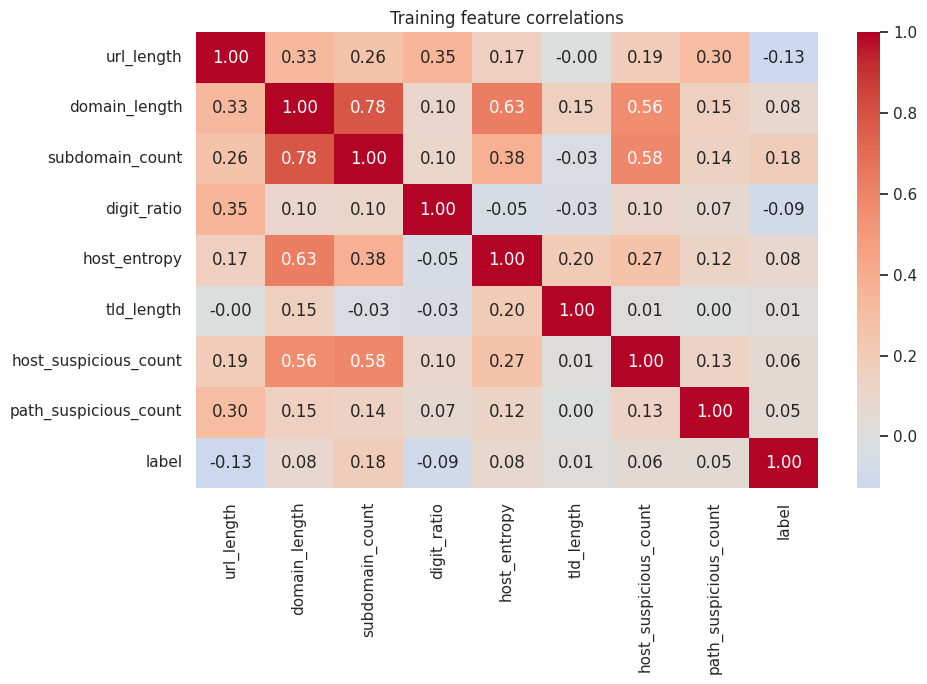

In [38]:
cols = ["url_length", "domain_length", "subdomain_count", "digit_ratio",
        "host_entropy", "tld_length", "host_suspicious_count",
        "path_suspicious_count", "label"]

plt.figure(figsize=(10, 7))
sns.heatmap(tmp[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Training feature correlations")
plt.tight_layout()
plt.show()

### Common training suffixes

Compare the ten most frequent training suffixes. An empty suffix means the parser did not find one. Encoding will handle it as a category.

In [39]:
top = train_features["tld"].value_counts().head(10).index
tmp = pd.DataFrame({"tld": train_features["tld"], "label": y_train})
pd.crosstab(tmp["tld"], tmp["label"]).reindex(top)

label,0,1
tld,,
com,240170,38797
org,31350,8263
net,15191,4340
edu,5737,2595
ca,6639,545
blogspot.com,6264,350
co.uk,4255,1703
com.br,1608,944
gov,2179,298


**Feature Type Identification**

Inspect the data types of the training features and separate them into numerical and categorical features.

Numerical Features: Contain numeric values.
Categorical Features: Contain non-numeric values that may require encoding.

In [40]:
print (X_train.dtypes)

url_length                 int64
domain_length              int64
path_length                int64
query_length               int64
dot_count                  int64
digit_count                int64
hyphen_count               int64
at_count                   int64
slash_count                int64
question_count             int64
equal_count                int64
amp_count                  int64
percent_count              int64
underscore_count           int64
special_count              int64
subdomain_count            int64
host_digit_count           int64
host_hyphen_count          int64
digit_ratio              float64
path_depth                 int64
param_count                int64
has_ip                     int64
has_punycode               int64
suspicious_count           int64
host_suspicious_count      int64
path_suspicious_count      int64
host_entropy             float64
tld                       object
tld_length                 int64
dtype: object


In [41]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()

categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print("Numeric Features:")
print(numeric_features)

print("Categorical Features:")
print(categorical_features)

Numeric Features:
['url_length', 'domain_length', 'path_length', 'query_length', 'dot_count', 'digit_count', 'hyphen_count', 'at_count', 'slash_count', 'question_count', 'equal_count', 'amp_count', 'percent_count', 'underscore_count', 'special_count', 'subdomain_count', 'host_digit_count', 'host_hyphen_count', 'digit_ratio', 'path_depth', 'param_count', 'has_ip', 'has_punycode', 'suspicious_count', 'host_suspicious_count', 'path_suspicious_count', 'host_entropy', 'tld_length']
Categorical Features:
['tld']


**Missing Values Analysis**

Count missing values in each feature.
Calculate the total number of missing values in each dataset.
Identify the need for imputation before model training.

This step helps ensure that missing data is handled consistently during preprocessing.

In [42]:
print("Missing values in X_train:")
print(X_train.isna().sum())

print("\nMissing values in X_test:")
print(X_test.isna().sum())

Missing values in X_train:
url_length               0
domain_length            0
path_length              0
query_length             0
dot_count                0
digit_count              0
hyphen_count             0
at_count                 0
slash_count              0
question_count           0
equal_count              0
amp_count                0
percent_count            0
underscore_count         0
special_count            0
subdomain_count          0
host_digit_count         0
host_hyphen_count        0
digit_ratio              0
path_depth               0
param_count              0
has_ip                   0
has_punycode             0
suspicious_count         0
host_suspicious_count    0
path_suspicious_count    0
host_entropy             0
tld                      0
tld_length               0
dtype: int64

Missing values in X_test:
url_length               0
domain_length            0
path_length              0
query_length             0
dot_count                0
digit_count    

In [43]:
print("Total missing in training:",X_train.isna().sum().sum())

print("Total missing in test:", X_test.isna().sum().sum())

Total missing in training: 0
Total missing in test: 0


**Preprocessing Tools**

Import the scikit-learn tools to build a preprocessing piplines

In [44]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

**Define Feature Transformation Pipelines**

Create separate preprocessing pipelines for numerical and categorical features.
impute missing values using median and frequent value.

In [45]:
numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

In [46]:
categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])

**Applying Preprocessing to Training and Testing Data**

Fitting the preprocessor only on the training data helps prevent data leakage and ensures consistent transformations across both datasets.

In [47]:
preprocessor = ColumnTransformer(transformers=[("num", numeric_transformer, numeric_features),("cat", categorical_transformer, categorical_features)])

In [48]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

**Verify Processed Data Dimensions**

Display the dimensions of the processed training and testing datasets.

In [49]:
print("Processed training shape:", X_train_processed.shape)

print("Processed test shape:", X_test_processed.shape)

Processed training shape: (419021, 1039)
Processed test shape: (103037, 1039)



Check that the number of rows in each processed dataset matches the number of corresponding target labels.

This validation ensures that the features and labels remain correctly aligned after preprocessing.

In [50]:
print("Training labels aligned:",X_train_processed.shape[0] == y_train.shape[0])

print("Test labels aligned:",X_test_processed.shape[0] == y_test.shape[0])

Training labels aligned: True
Test labels aligned: True


**Validate Numerical Integrity**

Ensure all processed values are finite.

**The validation detects:**

NaN values.
Positive infinity (+inf).
Negative infinity (-inf).

In [51]:
def check_processed_data(data, name):
    if hasattr(data, "toarray"):
        data = data.toarray()

    print(f"{name} contains only finite values:",np.isfinite(data).all())


check_processed_data(X_train_processed, "X_train")
check_processed_data(X_test_processed, "X_test")

X_train contains only finite values: True
X_test contains only finite values: True


In [55]:
import time
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score

for name in ["X_train", "X_test", "y_train", "y_test", "train_df", "test_df",
             "numeric_features", "categorical_features"]:
    print(name, "" if name in globals() else " unknown")

TARGET_FPR = 0.05

def recall_at_fpr(y, p, target=TARGET_FPR):
    fpr, tpr, thr = roc_curve(y, p)
    i = np.where(fpr <= target)[0][-1]
    return tpr[i], fpr[i], thr[i]

groups = train_df["domain"].to_numpy()
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(X_train, y_train, groups=groups))

print("\n folds:", len(folds))
for k, (tr, va) in enumerate(folds):
    print(f"fold {k}: train={len(tr)}  val={len(va)}  phishing% val={y_train.iloc[va].mean()*100:.1f}")

X_train 
X_test 
y_train 
y_test 
train_df 
test_df 
numeric_features 
categorical_features 

 folds: 5
fold 0: train=340127  val=78894  phishing% val=19.1
fold 1: train=335373  val=83648  phishing% val=15.6
fold 2: train=336564  val=82457  phishing% val=19.6
fold 3: train=337912  val=81109  phishing% val=20.8
fold 4: train=326108  val=92913  phishing% val=16.1


In [56]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier


def make_preprocessor(scale=True):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    num_tf = Pipeline(steps=steps)

    cat_tf = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                  min_frequency=100,
                                  sparse_output=False)),
    ])

    return ColumnTransformer(transformers=[
        ("num", num_tf, numeric_features),
        ("cat", cat_tf, categorical_features),
    ])


models = {
    "Dummy": Pipeline([
        ("pre", make_preprocessor(scale=False)),
        ("clf", DummyClassifier(strategy="prior")),
    ]),
    "LogReg": Pipeline([
        ("pre", make_preprocessor(scale=True)),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]),
}


def run_cv(name, model):
    t0 = time.time()
    oof_pred = np.zeros(len(X_train))
    for k, (tr, va) in enumerate(folds):
        model.fit(X_train.iloc[tr], y_train.iloc[tr])
        oof_pred[va] = model.predict_proba(X_train.iloc[va])[:, 1]
        print(f"  {name} fold {k} done")
    rec, fpr, thr = recall_at_fpr(y_train, oof_pred)
    result = {
        "model": name,
        "recall@5%FPR": round(rec, 4),
        "AP": round(average_precision_score(y_train, oof_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_train, oof_pred), 4),
        "seconds": round(time.time() - t0, 1),
    }
    return oof_pred, result


oof = {}
results = []
for name, model in models.items():
    oof[name], res = run_cv(name, model)
    results.append(res)

pd.DataFrame(results).set_index("model")

  Dummy fold 0 done
  Dummy fold 1 done
  Dummy fold 2 done
  Dummy fold 3 done
  Dummy fold 4 done
  LogReg fold 0 done
  LogReg fold 1 done
  LogReg fold 2 done
  LogReg fold 3 done
  LogReg fold 4 done


,recall@5%FPR,AP,ROC-AUC,seconds
model,,,,
Dummy,0.0000,0.1688,0.4624,18.2
LogReg,0.2556,0.4510,0.8184,160.1


In [57]:
from sklearn.ensemble import HistGradientBoostingClassifier

models["HistGB"] = Pipeline([
    ("pre", make_preprocessor(scale=False)),
    ("clf", HistGradientBoostingClassifier(
        learning_rate=0.1,
        max_iter=300,
        random_state=42,
    )),
])

oof["HistGB"], res = run_cv("HistGB", models["HistGB"])
results.append(res)

pd.DataFrame(results).set_index("model")

  HistGB fold 0 done
  HistGB fold 1 done
  HistGB fold 2 done
  HistGB fold 3 done
  HistGB fold 4 done


,recall@5%FPR,AP,ROC-AUC,seconds
model,,,,
Dummy,0.0000,0.1688,0.4624,18.2
LogReg,0.2556,0.4510,0.8184,160.1
HistGB,0.6969,0.8243,0.9369,461.4


In [58]:
from sklearn.ensemble import RandomForestClassifier

models["RandomForest"] = Pipeline([
    ("pre", make_preprocessor(scale=False)),
    ("clf", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42,
    )),
])

oof["RandomForest"], res = run_cv("RandomForest", models["RandomForest"])
results.append(res)

pd.DataFrame(results).set_index("model")

  RandomForest fold 0 done
  RandomForest fold 1 done
  RandomForest fold 2 done
  RandomForest fold 3 done
  RandomForest fold 4 done


,recall@5%FPR,AP,ROC-AUC,seconds
model,,,,
Dummy,0.0000,0.1688,0.4624,18.2
LogReg,0.2556,0.4510,0.8184,160.1
HistGB,0.6969,0.8243,0.9369,461.4
RandomForest,0.6788,0.8195,0.9342,1002.3


In [59]:
import joblib

joblib.dump(oof, "oof_predictions.joblib")

best_name = "HistGB"
rec, fpr, thr = recall_at_fpr(y_train, oof[best_name])

print(f"Model     : {best_name}")
print(f"Threshold : {thr:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"FPR       : {fpr:.4f}  (target {TARGET_FPR})")

from sklearn.metrics import precision_score, confusion_matrix
pred_val = (oof[best_name] >= thr).astype(int)
tn, fp, fn, tp = confusion_matrix(y_train, pred_val).ravel()
print(f"Precision : {precision_score(y_train, pred_val):.4f}")
print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")

Model     : HistGB
Threshold : 0.4902
Recall    : 0.6969
FPR       : 0.0491  (target 0.05)
Precision : 0.7589
TP=53033  FP=16851  FN=23070  TN=326067


In [60]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier


def strip_scheme(s):
    s = re.sub(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", "", s)
    return s[2:] if s.startswith("//") else s


text_train = train_df["url"].map(strip_scheme).str.lower().reset_index(drop=True)

text_model = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(3, 5), min_df=5,
                              max_features=300000, sublinear_tf=True,
                              dtype=np.float32)),
    ("clf", SGDClassifier(loss="log_loss", alpha=1e-6, max_iter=20,
                          tol=None, random_state=42)),
])

t0 = time.time()
oof_text = np.zeros(len(text_train))
for k, (tr, va) in enumerate(folds):
    text_model.fit(text_train.iloc[tr], y_train.iloc[tr])
    oof_text[va] = text_model.predict_proba(text_train.iloc[va])[:, 1]
    print(f"  TextNgram fold {k} done")
oof["TextNgram"] = oof_text

rec, fpr, thr_t = recall_at_fpr(y_train, oof_text)
print(f"\nTextNgram alone: recall@5%FPR={rec:.4f}  AP={average_precision_score(y_train, oof_text):.4f}  "
      f"AUC={roc_auc_score(y_train, oof_text):.4f}  ({time.time()-t0:.0f}s)")

rows = []
for w in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 1.0]:
    p = w * oof["TextNgram"] + (1 - w) * oof["HistGB"]
    r, f, t = recall_at_fpr(y_train, p)
    rows.append({"w_text": w, "recall@5%FPR": round(r, 4),
                 "AP": round(average_precision_score(y_train, p), 4),
                 "ROC-AUC": round(roc_auc_score(y_train, p), 4)})
pd.DataFrame(rows).set_index("w_text")

joblib.dump(oof, "oof_predictions.joblib")

  TextNgram fold 0 done
  TextNgram fold 1 done
  TextNgram fold 2 done
  TextNgram fold 3 done
  TextNgram fold 4 done

TextNgram alone: recall@5%FPR=0.8434  AP=0.8848  AUC=0.9644  (555s)


['oof_predictions.joblib']

In [61]:
rows = []
for w in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    p = w * oof["TextNgram"] + (1 - w) * oof["HistGB"]
    r, f, t = recall_at_fpr(y_train, p)
    rows.append({"w_text": w,
                 "recall@5%FPR": round(r, 4),
                 "AP": round(average_precision_score(y_train, p), 4),
                 "ROC-AUC": round(roc_auc_score(y_train, p), 4)})

blend_table = pd.DataFrame(rows).set_index("w_text")
print(blend_table)

        recall@5%FPR      AP  ROC-AUC
w_text                               
0.0           0.6969  0.8243   0.9369
0.2           0.7591  0.8674   0.9550
0.3           0.7937  0.8833   0.9604
0.4           0.8251  0.8953   0.9644
0.5           0.8430  0.9027   0.9670
0.6           0.8555  0.9058   0.9686
0.7           0.8611  0.9059   0.9693
0.8           0.8574  0.9032   0.9692
0.9           0.8518  0.8972   0.9681
1.0           0.8434  0.8848   0.9644


In [62]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

W_TEXT = 0.7
p_val = W_TEXT * oof["TextNgram"] + (1 - W_TEXT) * oof["HistGB"]

rec, fpr, thr_final = recall_at_fpr(y_train, p_val)
pred_val = (p_val >= thr_final).astype(int)
tn, fp, fn, tp = confusion_matrix(y_train, pred_val).ravel()

print(f"Weight (text)  : {W_TEXT}")
print(f"Threshold      : {thr_final:.4f}")
print(f"Recall         : {rec:.4f}")
print(f"FPR            : {fpr:.4f}  (target {TARGET_FPR})")
print(f"Precision      : {precision_score(y_train, pred_val):.4f}")
print(f"F1             : {f1_score(y_train, pred_val):.4f}")
print(f"Accuracy       : {(tp + tn) / (tp + tn + fp + fn):.4f}")
print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")

joblib.dump({"w_text": W_TEXT, "threshold": float(thr_final)}, "final_config.joblib")

Weight (text)  : 0.7
Threshold      : 0.2893
Recall         : 0.8611
FPR            : 0.0500  (target 0.05)
Precision      : 0.7926
F1             : 0.8255
Accuracy       : 0.9339
TP=65536  FP=17144  FN=10567  TN=325774


['final_config.joblib']

HistGB fitted (111s)
TextNgram fitted (120s)

=== TEST RESULTS ===
Recall    : 0.8582
FPR       : 0.0517  (target 0.05)
Precision : 0.7772
F1        : 0.8157
Accuracy  : 0.9327
AP        : 0.8977
ROC-AUC   : 0.9700
TP=15348  FP=4399  FN=2536  TN=80754


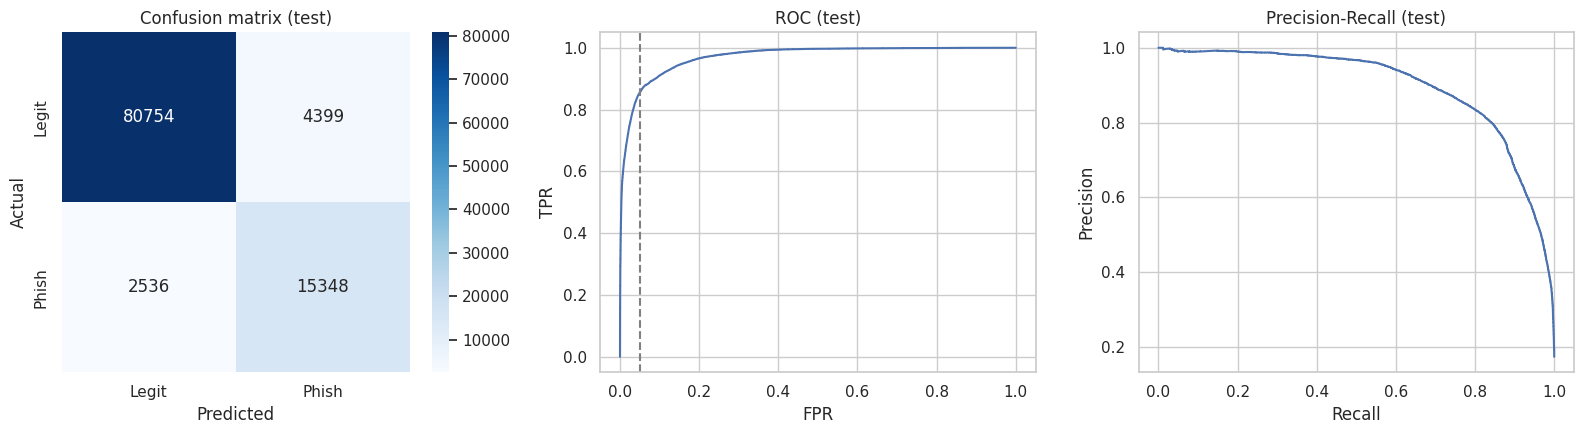

['phish_model.joblib']

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (precision_recall_curve, precision_score,
                             recall_score, f1_score, confusion_matrix)

cfg = joblib.load("final_config.joblib")
W_TEXT, THRESHOLD = cfg["w_text"], cfg["threshold"]

# Final fit on the full training set
t0 = time.time()
final_hgb = models["HistGB"]
final_hgb.fit(X_train, y_train)
print(f"HistGB fitted ({time.time()-t0:.0f}s)")

t0 = time.time()
text_test = test_df["url"].map(strip_scheme).str.lower().reset_index(drop=True)
final_text = text_model
final_text.fit(text_train, y_train)
print(f"TextNgram fitted ({time.time()-t0:.0f}s)")

# Test predictions with the frozen weight and threshold
p_hgb = final_hgb.predict_proba(X_test)[:, 1]
p_text = final_text.predict_proba(text_test)[:, 1]
p_test = W_TEXT * p_text + (1 - W_TEXT) * p_hgb
pred = (p_test >= THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print("\n=== TEST RESULTS ===")
print(f"Recall    : {tp / (tp + fn):.4f}")
print(f"FPR       : {fp / (fp + tn):.4f}  (target {TARGET_FPR})")
print(f"Precision : {precision_score(y_test, pred):.4f}")
print(f"F1        : {f1_score(y_test, pred):.4f}")
print(f"Accuracy  : {(tp + tn) / (tp + tn + fp + fn):.4f}")
print(f"AP        : {average_precision_score(y_test, p_test):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, p_test):.4f}")
print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")

# Plots
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["Legit", "Phish"], yticklabels=["Legit", "Phish"])
ax[0].set_title("Confusion matrix (test)")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")
f_, t_, _ = roc_curve(y_test, p_test)
ax[1].plot(f_, t_)
ax[1].axvline(TARGET_FPR, ls="--", c="gray")
ax[1].set_title("ROC (test)")
ax[1].set_xlabel("FPR")
ax[1].set_ylabel("TPR")
pr, rc, _ = precision_recall_curve(y_test, p_test)
ax[2].plot(rc, pr)
ax[2].set_title("Precision-Recall (test)")
ax[2].set_xlabel("Recall")
ax[2].set_ylabel("Precision")
plt.tight_layout()
plt.show()

# Save everything
joblib.dump({"hgb": final_hgb, "text": final_text,
             "w_text": W_TEXT, "threshold": THRESHOLD,
             "features": X_train.columns.tolist()}, "phish_model.joblib")

In [64]:
err = test_df[["url", "domain", "label"]].copy()
err["p"] = p_test
err["pred"] = pred
err["scheme_known"] = test_features["scheme_known"].to_numpy()
err["has_www"] = err["url"].map(strip_scheme).str.lower().str.startswith("www.")

pd.set_option("display.max_colwidth", 100)

print("Missed phishing (lowest scores):")
display(err[(err.label == 1) & (err.pred == 0)].sort_values("p").head(15)[["url", "p"]])

print("False alarms (highest scores):")
display(err[(err.label == 0) & (err.pred == 1)].sort_values("p", ascending=False).head(15)[["url", "p"]])


def group_report(col):
    rows = []
    for val, g in err.groupby(col):
        pos = g[g.label == 1]
        neg = g[g.label == 0]
        rows.append({
            col: val,
            "n": len(g),
            "phish_share": round(g.label.mean(), 3),
            "recall": round((pos.pred == 1).mean(), 4) if len(pos) else np.nan,
            "FPR": round((neg.pred == 1).mean(), 4) if len(neg) else np.nan,
        })
    return pd.DataFrame(rows).set_index(col)


print("\nBy explicit scheme:")
print(group_report("scheme_known"))
print("\nBy leading www:")
print(group_report("has_www"))

Missed phishing (lowest scores):


,url,p
83535,http://tu762.com/,0.004358
83139,http://bdkdkb.com/,0.004736
83621,https://kergaukr.com/feed/posts/chelsea-clinton-calls-out-national-enquirer-for-attacks-against-...,0.005422
83622,http://kergaukr.com/feed/posts/chelsea-clinton-calls-out-national-enquirer-for-attacks-against-h...,0.005422
85135,https://fndtmc.com/,0.006716
8228,http://paypal.com.us.login.cgi-bin.dispatch.confirmed.webscr.account64x28423x224j5m56403o2djvrep...,0.006927
102749,grognardia.blogspot.com/2011/02/complete-history-and-evolution-of.html,0.007610
83623,https://kergaukr.com/feed/posts/goldmans-president-david-solomon-to-become-ceo-on-oct-1,0.007835
97588,randazza.wordpress.com/2010/08/20/no-man-is-an-island-but-wipo-is-no-man/,0.007890
27191,http://hindutemplestjohns.ca/images/redir.php,0.008353


False alarms (highest scores):


,url,p
91865,www.dhl-menu.de,0.990288
88241,www.online-mediacents.com,0.982309
88595,www.riauhost.com,0.980901
86728,www.twivvter.com,0.980099
93404,updateinformation.bankofamerica.com.ntamarine.com,0.978695
85795,www.soufielatam.com,0.978374
88304,chaseonline.clubdeportivokuroobi.com,0.976099
89350,www.admarkt-marktplaats.com,0.975755
85862,www.147media.nl,0.975069
89728,www.arataip.go.ro,0.970590



By explicit scheme:
                  n  phish_share  recall     FPR
scheme_known                                    
0             90513        0.137  0.9314  0.0541
1             12524        0.438  0.6927  0.0246

By leading www:
             n  phish_share  recall     FPR
has_www                                    
False    93215        0.117  0.7853  0.0344
True      9822        0.714  0.9712  0.5582
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [65]:
def predict_url(url, bundle=None):
    bundle = bundle or joblib.load("phish_model.joblib")
    url = url.strip()
    try:
        feats = pd.DataFrame([get_features(url)]).drop(columns=["scheme_known", "has_https"])
        feats = feats[bundle["features"]]
    except (ValueError, ZeroDivisionError):
        return {"url": url, "error": "could not parse this URL"}

    p_hgb = bundle["hgb"].predict_proba(feats)[0, 1]
    p_txt = bundle["text"].predict_proba(pd.Series([strip_scheme(url).lower()]))[0, 1]
    p = bundle["w_text"] * p_txt + (1 - bundle["w_text"]) * p_hgb

    return {
        "url": url,
        "phishing_probability": round(float(p), 4),
        "class": "phishing" if p >= bundle["threshold"] else "legitimate",
    }


bundle = joblib.load("phish_model.joblib")
for u in ["https://www.google.com/",
          "http://192.0.2.1/verify/account",
          "secure-login-update.example.com/confirm?id=123"]:
    print(predict_url(u, bundle))

{'url': 'https://www.google.com/', 'phishing_probability': 0.6877, 'class': 'phishing'}
{'url': 'http://192.0.2.1/verify/account', 'phishing_probability': 0.8197, 'class': 'phishing'}
{'url': 'secure-login-update.example.com/confirm?id=123', 'phishing_probability': 0.3695, 'class': 'phishing'}
